In [21]:
#loading libraries:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import L1,L2,L1L2
from matplotlib import pyplot as plt
import keras_tuner as kt

In [2]:
df = pd.read_csv("cardekho.csv")
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,seats
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,5.0
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,5.0
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,5.0
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,5.0
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,5.0


In [3]:
df.isnull().sum()

year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
seats            221
dtype: int64

In [4]:
df["mileage"] = df["mileage"].fillna(df["mileage"].mean())
df["engine"] = df["engine"].fillna(df["engine"].mean())
df["seats"] = df["seats"].fillna(df["seats"].mean())

In [5]:
df.duplicated().sum()

np.int64(1222)

In [7]:
df.drop_duplicates(inplace=True)
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,seats
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,5.0
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,5.0
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,5.0
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,5.0
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,5.0


In [8]:
#encoding:
label = LabelEncoder()
df["encoded_fuel"] = label.fit_transform(df["fuel"])
var = dict(zip(df["fuel"],df["encoded_fuel"]))
print(var)

df["encoded_seller"] = label.fit_transform(df["seller_type"])
var1 = dict(zip(df["seller_type"],df["encoded_seller"]))
print(var1)

df["encoded_trans"] = label.fit_transform(df["transmission"])
var2 = dict(zip(df["transmission"],df["encoded_trans"]))
print(var2)

df["encoded_owner"] = label.fit_transform(df["owner"])
var3 = dict(zip(df["owner"],df["encoded_owner"]))
print(var3)

{'Diesel': 1, 'Petrol': 3, 'LPG': 2, 'CNG': 0}
{'Individual': 1, 'Dealer': 0, 'Trustmark Dealer': 2}
{'Manual': 1, 'Automatic': 0}
{'First Owner': 0, 'Second Owner': 2, 'Third Owner': 4, 'Fourth & Above Owner': 1, 'Test Drive Car': 3}


In [9]:
df.drop(columns=["fuel","seller_type","transmission","owner"],inplace=True)

In [10]:
#feature selection:
x = df.drop(columns=["selling_price"])
y = df["selling_price"]

In [12]:
#data splitting:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [13]:
#scaling:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [14]:
#learning rate: learning timw taken by one model to shift to another

In [24]:
#ANN architecture: choice are given for nodes when 
#input layer:
def build_model(hp):
    model=Sequential()
    model.add(Dense(units=hp.Choice("unit_1", values=[32,64,128,256]),
                    activation="sigmoid",
                    input_dim=(9)))
    model.add(Dense(units=hp.Choice("unit_2", values =[64,128,256,512]),
                    activation="relu"))
    model.add(Dense(units=hp.Choice("unit_3", values = [128,256,512]),
                    activation="relu"))
    model.add(Dense(units=hp.Choice("unit_4", values = [128,256,512]),
                    activation="relu"))
    model.add(Dense(1,activation="linear"))

    model.compile(optimizer=Adam(learning_rate=hp.Choice("learning_rate", values=[0.01,0.001,0.0001])),
                  loss = "mean_squared_error",
                  metrics= ["r2_score"])
    return model

In [17]:
%pip install keras-tuner


   ---------------------------------------- 0/2 [kt-legacy]
   ---------------------------------------- 0/2 [kt-legacy]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   --------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
#tuning paramerter:
tuner = kt.Hyperband(
    build_model,
    objective=kt.Objective("val_r2_score", direction = "max"), #if wrote val_loss then direction = min
    max_epochs = 20, # these are the epochs for the nodes finding with best model
    factor = 3,
    directory = r"C:\Users\Anushkha Bhagra\Downloads\deep learning\ANN\my_tuner",
    project_name = "car_price_ann",
    overwrite = True
)
tuner.search_space_summary()

Search space summary
Default search space size: 5
unit_1 (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128, 256], 'ordered': True}
unit_2 (Choice)
{'default': 64, 'conditions': [], 'values': [64, 128, 256, 512], 'ordered': True}
unit_3 (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 512], 'ordered': True}
unit_4 (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 512], 'ordered': True}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


In [28]:
#
tuner.search(
    x_train_scaled,
    y_train,
    epochs=20,
    validation_split = 0.2,
    callbacks=[EarlyStopping(monitor="val_loss",patience=5)]
)

Trial 26 Complete [00h 00m 26s]
val_r2_score: 0.6252534985542297

Best val_r2_score So Far: 0.7924379110336304
Total elapsed time: 00h 07m 01s


In [31]:
#print best hyperparameter found:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best values found by keras tuner:")

print("layer 1 units :", best_hps.get("unit_1"))
print("layer 2 units :", best_hps.get("unit_2"))
print("layer 3 units :", best_hps.get("unit_3"))
print("layer 4 units :", best_hps.get("unit_4"))
print("Learning rate:", best_hps.get("learning_rate"))

Best values found by keras tuner:
layer 1 units : 64
layer 2 units : 256
layer 3 units : 128
layer 4 units : 256
Learning rate: 0.01


In [32]:
#build and train the best model:
best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

early_stopping_final = EarlyStopping(
    monitor = "val_loss",
    mode = "min",
    patience= 5,
    restore_best_weights= True,
    verbose=1
    )

history = best_model.fit(
    x_train_scaled,
    y_train,
    epochs=50,
    validation_split=0.2,
    callbacks=[early_stopping_final]
)

c:\Users\Anushkha Bhagra\Downloads\deep learning\ANN\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,457 (326.00 KB)

 Trainable params: 83,457 (326.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 276054802432.0000 - r2_score: 0.0581 - val_loss: 155735343104.0000 - val_r2_score: 0.4250
Epoch 2/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 159015075840.0000 - r2_score: 0.4575 - val_loss: 128091693056.0000 - val_r2_score: 0.5271
Epoch 3/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 131376496640.0000 - r2_score: 0.5518 - val_loss: 117773664256.0000 - val_r2_score: 0.5652
Epoch 4/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 120330436608.0000 - r2_score: 0.5894 - val_loss: 96118759424.0000 - val_r2_score: 0.6451
Epoch 5/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 107908612096.0000 - r2_score: 0.6318 - val_loss: 96489816064.0000 - val_r2_score: 0.6437
Epoch 6/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 103316889600.0000 - r2_score: 0.6475 - val_loss: 91870216192.0000 - val_r2_score: 0.6608
Epoch 7/50
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 98329559040.0000 - r2_score: 0.6645 - val_

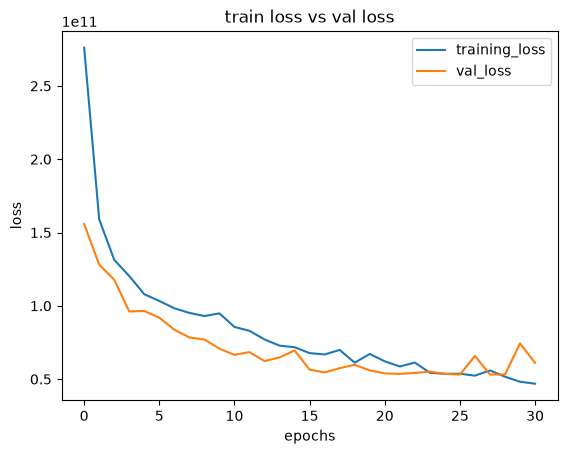

In [ ]:
#plot the graphs:
plt.plot(history.history["loss"],label="training_loss")
plt.plot(history.history["val_loss"],label="val_loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("train loss vs val loss")
plt.legend()
plt.show()

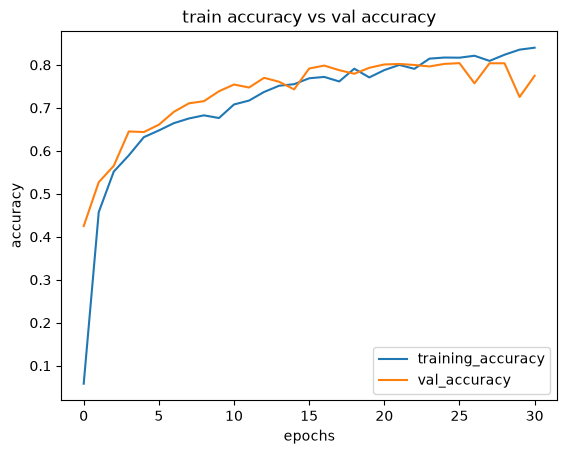

In [35]:
#plot the graphs:
plt.plot(history.history["r2_score"],label="training_accuracy")
plt.plot(history.history["val_r2_score"],label="val_accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("train accuracy vs val accuracy")
plt.legend()
plt.show()